In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from scipy.linalg import inv
from ripser import ripser
from persim import wasserstein
from dataclasses import dataclass
from typing import Dict, Literal, List, Tuple
from numpy.typing import NDArray


pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 200)
P = "data/"

In [3]:
def pct_to_decimal(df: pd.DataFrame) -> pd.DataFrame:
    """Heuristic guess: if mean abs value > 0.5 it's probably percent, convert to decimal."""
    if df.abs().mean().mean() > 0.5:
        return df / 100.0
    return df


In [4]:
# ----- Fama-French 10/30 daily industry returns -----
ff10 = pd.read_csv(P + "ff_10.csv")
ff30 = pd.read_csv(P + "ff_30.csv")

# Parse YYYYMMDD dates
ff10['Date'] = pd.to_datetime(ff10['Date'], format="%Y%m%d")
ff30['Date'] = pd.to_datetime(ff30['Date'], format="%Y%m%d")
ff10 = ff10.set_index('Date').sort_index()
ff30 = ff30.set_index('Date').sort_index()

# Convert % -> decimals
ff10 = pct_to_decimal(ff10)
ff30 = pct_to_decimal(ff30)

# ----- VIX daily close -----
vix = pd.read_csv(P + "vix.csv")
vix['Date'] = pd.to_datetime(vix['Date'])
vix = vix.set_index('Date').sort_index()
vix_daily = vix['Close'].astype(float)

In [5]:
spy_raw = pd.read_csv(P + "spy.csv", header=None, skiprows=2)

def try_parse_date(x):
    try:
        return pd.to_datetime(x, format="%Y-%m-%d")
    except Exception:
        return pd.NaT

parsed = spy_raw[0].apply(try_parse_date)
spy_use = spy_raw[parsed.notna()].copy()
spy_use[0] = pd.to_datetime(spy_use[0], format="%Y-%m-%d")

# Keep the last numeric column as Adj Close
# If there are exactly 2 usable columns, rename accordingly; otherwise pick the last column.
if spy_use.shape[1] == 2:
    spy_use.columns = ['Date','AdjClose']
else:
    cols = ['Date'] + [f'col{i}' for i in range(1, spy_use.shape[1])]
    spy_use.columns = cols
    spy_use = spy_use[['Date', cols[-1]]].rename(columns={cols[-1]: 'AdjClose'})


spy_use = spy_use.set_index('Date').sort_index()
# If monthly-level file: make it month-end; if daily-level file: resample to month-end last
if spy_use.index.inferred_type in ("datetime64", "datetime64ns"):
    # If it already looks monthly (few rows per year), still take month-end .resample("M").last()
    spy_monthly_px = spy_use['AdjClose'].resample('M').last()
else:
    raise ValueError("SPY date index not parsed.")

spy_ret_m = spy_monthly_px.pct_change().dropna()
spy_ret_m.name = "R_spy"


In [6]:
# Monthly T-Bill (already decimals)
tbill = pd.read_csv(P + "tbill_monthly.csv")
tbill['date'] = pd.to_datetime(tbill['date'])
tbill = tbill.set_index('date').sort_index()
tbill_m = tbill['R_tbill'].astype(float)
tbill_m.name = "R_tbill"

# Normalize both to month-end index
spy_ret_m.index = spy_ret_m.index.to_period("M").to_timestamp("M")
tbill_m.index   = tbill_m.index.to_period("M").to_timestamp("M")
tbill_m = tbill_m.reindex(spy_ret_m.index).ffill()

In [7]:
print(ff10.shape, ff30.shape, vix_daily.shape, spy_ret_m.shape, tbill_m.shape)

(8222, 10) (8222, 30) (8286,) (393,) (393,)


In [8]:
# ripser wants points as (n_points, dim). We'll use a 60 x N window of daily returns.
def diagrams_for_window(window_60xN: np.ndarray, maxdim: int = 1) -> List[NDArray]:
    """
    Return [D0, D1] persistence diagrams (birth, death) for dims 0 and 1 using Vietoris–Rips.
    """
    res = ripser(window_60xN, maxdim=maxdim, metric='euclidean')
    return res['dgms']  # list of arrays: dgms[0] (H0), dgms[1] (H1)


In [9]:
def _sanitize_dgm(dgm: np.ndarray) -> np.ndarray:
    """
    Ensure (n,2) birth-death, replace inf deaths with a large finite cap
    so persim doesn't choke on some versions.
    """
    if dgm is None or len(dgm) == 0:
        return np.empty((0, 2), dtype=float)
    D = np.asarray(dgm, dtype=float)
    if D.shape[1] > 2:
        D = D[:, :2]
    # replace +/-inf deaths with (max_finite_death + eps)
    deaths = D[:, 1]
    finite = np.isfinite(deaths)
    if finite.any():
        cap = deaths[finite].max() + 1e-6
        deaths[~finite] = cap
        D[:, 1] = deaths
    else:
        # all deaths are inf -> set a small increasing ladder to avoid NaNs
        n = len(D)
        D[:, 1] = np.linspace(1.0, 1.0 + 1e-6*(n-1), n)
    return D

In [10]:
def wasserstein_union(dgm_prev, dgm_curr) -> float:
    """
    Single Wasserstein on H0 union H1.
    Concatenate birth–death pairs from H0 and H1 (after sanitizing inf deaths).
    """
    empty = np.empty((0, 2), dtype=float)

    A0 = _sanitize_dgm(dgm_prev[0]) if len(dgm_prev) > 0 else empty
    A1 = _sanitize_dgm(dgm_prev[1]) if len(dgm_prev) > 1 else empty
    B0 = _sanitize_dgm(dgm_curr[0]) if len(dgm_curr) > 0 else empty
    B1 = _sanitize_dgm(dgm_curr[1]) if len(dgm_curr) > 1 else empty

    A = np.vstack([x for x in (A0, A1) if x.size]) if (A0.size or A1.size) else empty
    B = np.vstack([x for x in (B0, B1) if x.size]) if (B0.size or B1.size) else empty

    if A.size == 0 and B.size == 0:
        return 0.0
    return float(wasserstein(A, B, matching=False))

In [11]:
@dataclass
class PHTIConfig:
    win_days: int = 60       # window for diagrams
    smooth_days: int = 60    # SMA of daily W
    memory_months: int = 60  # trailing months for quintiles

In [12]:
def compute_phti_daily(sector_daily: pd.DataFrame, cfg: PHTIConfig, return_raw: bool = False) -> pd.Series:
    """
    sector_daily: daily returns in decimals, columns are sectors, DateTimeIndex (business days).
    Returns: daily raw PHTI (already smoothed by 60d SMA at the end).
    """
    sector_daily = sector_daily.sort_index()
    W_raw = pd.Series(index=sector_daily.index, dtype=float)
    # precompute diagrams for each day t using the 60-day window ending at t
    dgms_list: List[Tuple[pd.Timestamp, List[NDArray]]] = []
    for end_i in range(cfg.win_days-1, len(sector_daily)):
        end_dt = sector_daily.index[end_i]
        block = sector_daily.iloc[end_i-cfg.win_days+1:end_i+1].values
        dgms = diagrams_for_window(block, maxdim=1)
        dgms_list.append((end_dt, dgms))
    # wasserstein distance between consecutive diagrams
    for i in range(1, len(dgms_list)):
        t, d_curr = dgms_list[i]
        _, d_prev = dgms_list[i-1]
        W_raw.loc[t] = wasserstein_union(d_prev, d_curr)
    # Smooth with 60-day SMA
    W_sm = W_raw.rolling(cfg.smooth_days, min_periods=1).mean()
    W_sm.name = "PHTI_daily"
    return W_sm


In [13]:
def monthend_quintile_weights(signal_m: pd.Series, memory_months: int, scheme: Literal["WCP","FE","FEL"]="WCP") -> pd.Series:
    """
    Map monthly turbulence values to S&P 500 exposure weights using trailing 60-month quintiles (Table 2).
    """
    qnames = {1:"q1",2:"q2",3:"q3",4:"q4",5:"q5"}
    # exposure tables (weights in % of SPX; cash goes to T-bill)
    WCP = {1:100, 2:100, 3:100, 4:100, 5:0}
    FE  = {1:100, 2: 80, 3: 60, 4: 40, 5:20}
    FEL = {1:120, 2:110, 3: 90, 4: 60, 5:20}
    rule = {"WCP": WCP, "FE": FE, "FEL": FEL}[scheme]

    weights = pd.Series(index=signal_m.index, dtype=float)
    for i in range(memory_months, len(signal_m)):
        end_dt = signal_m.index[i]
        ref = signal_m.iloc[i-memory_months:i]      # trailing 60 months memory
        cut = pd.qcut(ref, 5, labels=[1,2,3,4,5])    # 1=lowest turbulence to 5=highest
        # determine which quintile current value would fall into vs trailing window
        q_edges = ref.quantile([0.2,0.4,0.6,0.8]).values
        x = signal_m.iloc[i]
        quint = 1 + (x > q_edges).sum()  # 1..5
        weights.loc[end_dt] = rule[quint]/100.0
    weights.name = f"w_{scheme}"
    return weights


In [14]:
# OTI (Original Turbulence Index: Mahalanobis distance variant)

def compute_oti_daily(sector_daily: pd.DataFrame, win_days: int = 60, smooth_days: int = 60) -> pd.Series:
    """
    dt = (y_t - mu)' Σ^{-1} (y_t - mu), rolling mu, Σ over last 60 days. Then 60d SMA.
    """
    X = sector_daily.sort_index().copy()
    dt = pd.Series(index=X.index, dtype=float)
    for end_i in range(win_days-1, len(X)):
        y = X.iloc[end_i].values
        block = X.iloc[end_i-win_days+1:end_i+1].values
        mu = block.mean(axis=0)
        S = np.cov(block.T, bias=False)
        try:
            Sinv = inv(S)
        except np.linalg.LinAlgError:
            # regularize if singular
            Sinv = inv(S + 1e-6*np.eye(S.shape[0]))
        diff = y - mu
        dt.iloc[end_i] = float(diff @ Sinv @ diff.T)
    return dt.rolling(smooth_days, min_periods=1).mean().rename("OTI_daily")


In [15]:
# Convert daily indicator to monthly turbulence index (month-end)

def daily_to_monthly_end(ind_daily: pd.Series) -> pd.Series:
    return ind_daily.dropna().resample("M").last()

def build_vix_signal(vix_daily: pd.Series, smooth_days: int = 60) -> pd.Series:
    """
    Build a VIX-based turbulence signal consistent with the 60-60-60 idea:
      - 60-day SMA on daily VIX
      - take month-end values
      - later: 60-month rolling window for quintiles

    vix_daily: daily VIX levels, float, DateTimeIndex.
    Returns: monthly VIX signal (smoothed, month-end).
    """
    vix_daily = vix_daily.sort_index().astype(float)
    vix_sm = vix_daily.rolling(smooth_days, min_periods=1).mean()
    vix_m = vix_sm.resample("M").last()
    vix_m.name = "VIX_smoothed"
    return vix_m


In [16]:
# VIX-based monthly signal (mirrors PHTI/OTI processing)
VIX_m = build_vix_signal(vix_daily, smooth_days=60)

# Align to SPY's month-end index and forward-fill in case of missing months
VIX_m = VIX_m.reindex(spy_ret_m.index).ffill()


In [17]:
# Backtest (out-of-sample, next-month application)

def backtest_spy_tbill(weights_spx: pd.Series, r_spy_m: pd.Series, r_tbill_m: pd.Series) -> pd.Series:
    """
    Apply month-end weight to NEXT month's return (pure out-of-sample, as in paper).
    """
    w = weights_spx.dropna()
    # align signals to returns: use signal at month t for month t+1 return
    w_lag = w.shift(1).reindex(r_spy_m.index).fillna(method='ffill')
    port = w_lag * r_spy_m + (1.0 - w_lag) * r_tbill_m
    return port.rename(f"PORT_{weights_spx.name}")


In [18]:
# quick performance helper
def ann_stats_m(monthly: pd.Series) -> Dict[str,float]:
    r = monthly.dropna()
    mu = 12 * r.mean()
    sd = np.sqrt(12) * r.std(ddof=1)
    sr = mu / sd if sd > 0 else np.nan
    return {"ann_ret": float(mu), "ann_vol": float(sd), "sharpe": float(sr)}


In [19]:
# RUN PIPELINE 

# choose 10- or 30-industry set for PHTI / OTI
use = ff10.copy()  # or ff30
use = use.dropna(how='any')

phti_cfg = PHTIConfig()  # 60/60/60, p=1
phti_daily = compute_phti_daily(use, phti_cfg)
PHTI_m = daily_to_monthly_end(phti_daily)

oti_daily = compute_oti_daily(use, win_days=60, smooth_days=60)
OTI_m = daily_to_monthly_end(oti_daily)

# VIX-based weights (same 60-month memory, same schemes)
w_vix_wcp = monthend_quintile_weights(VIX_m, memory_months=60, scheme="WCP")
w_vix_fe  = monthend_quintile_weights(VIX_m, memory_months=60, scheme="FE")
w_vix_fel = monthend_quintile_weights(VIX_m, memory_months=60, scheme="FEL")


# signals -> weights (pick a scheme: "WCP", "FE", or "FEL")
w_phti_wcp = monthend_quintile_weights(PHTI_m, memory_months=phti_cfg.memory_months, scheme="WCP")
w_phti_fe  = monthend_quintile_weights(PHTI_m, memory_months=phti_cfg.memory_months, scheme="FE")
w_phti_fel = monthend_quintile_weights(PHTI_m, memory_months=phti_cfg.memory_months, scheme="FEL")

w_oti_wcp  = monthend_quintile_weights(OTI_m,  memory_months=60, scheme="WCP")

# backtests (monthly)
bt_phti_wcp = backtest_spy_tbill(w_phti_wcp, spy_ret_m, tbill_m)
bt_phti_fe  = backtest_spy_tbill(w_phti_fe,  spy_ret_m, tbill_m)
bt_phti_fel = backtest_spy_tbill(w_phti_fel, spy_ret_m, tbill_m)
bt_oti_wcp  = backtest_spy_tbill(w_oti_wcp,  spy_ret_m, tbill_m)
bt_vix_wcp  = backtest_spy_tbill(w_vix_wcp,  spy_ret_m, tbill_m)
bt_vix_fe   = backtest_spy_tbill(w_vix_fe,   spy_ret_m, tbill_m)
bt_vix_fel  = backtest_spy_tbill(w_vix_fel,  spy_ret_m, tbill_m)


In [20]:
perf = {
    "PHTI(10)-WCP": ann_stats_m(bt_phti_wcp),
    "PHTI(10)-FE" : ann_stats_m(bt_phti_fe),
    "PHTI(10)-FEL": ann_stats_m(bt_phti_fel),
    "OTI(10)-WCP" : ann_stats_m(bt_oti_wcp),
    "VIX-WCP"     : ann_stats_m(bt_vix_wcp),
    "VIX-FE"      : ann_stats_m(bt_vix_fe),
    "VIX-FEL"     : ann_stats_m(bt_vix_fel),
    "SPY Buy&Hold": ann_stats_m(spy_ret_m.reindex(bt_phti_wcp.index))
}
print(perf)


{'PHTI(10)-WCP': {'ann_ret': 0.06774713656036736, 'ann_vol': 0.11219624862942716, 'sharpe': 0.6038271099787773}, 'PHTI(10)-FE': {'ann_ret': 0.06716835632190922, 'ann_vol': 0.0776604765072624, 'sharpe': 0.8648975559096393}, 'PHTI(10)-FEL': {'ann_ret': 0.07913890286638231, 'ann_vol': 0.10209632072466636, 'sharpe': 0.7751396162434131}, 'OTI(10)-WCP': {'ann_ret': 0.08518155413415826, 'ann_vol': 0.12715500018406214, 'sharpe': 0.6699032992084811}, 'VIX-WCP': {'ann_ret': 0.06996139988489689, 'ann_vol': 0.10984617407498494, 'sharpe': 0.6369033830631071}, 'VIX-FE': {'ann_ret': 0.06300366475509822, 'ann_vol': 0.08026988066372474, 'sharpe': 0.7848979496934844}, 'VIX-FEL': {'ann_ret': 0.07384896158136141, 'ann_vol': 0.10478182270717815, 'sharpe': 0.70478790761007}, 'SPY Buy&Hold': {'ann_ret': 0.11365193491993096, 'ann_vol': 0.14964409345037044, 'sharpe': 0.7594815959617123}}


In [21]:
# 1) lag sanity
w = w_phti_fe
check = pd.concat({
    "signal_t": w,
    "signal_t_used_for_returns": w.shift(1),
    "spy_ret": spy_ret_m,
}, axis=1).dropna()
print(check.head(3))  # visually confirm shift

# 2) tbill magnitude
print("tbill monthly mean:", tbill_m.mean(), "annualized ~", 12*tbill_m.mean())

# 3) start dates
print("PHTI_m start:", PHTI_m.dropna().index[0])
print("weights start (FE):", w_phti_fe.dropna().index[0])
print("backtest start:", bt_phti_fe.dropna().index[0])

# 4) exposure stats
for name, wts in {"FE": w_phti_fe, "FEL": w_phti_fel, "WCP": w_phti_wcp}.items():
    print(name, "avg w:", wts.mean(), "min:", wts.min(), "max:", wts.max())

# 5) max drawdown
def max_drawdown(r_m):
    curve = (1 + r_m.dropna()).cumprod()
    peak = curve.cummax()
    dd = (curve/peak - 1.0).min()
    return float(dd)
for lbl, ser in {
    "SPY": spy_ret_m.reindex(bt_phti_fe.index),
    "PHTI-FE": bt_phti_fe,
    "PHTI-FEL": bt_phti_fel,
    "PHTI-WCP": bt_phti_wcp,
}.items():
    print(lbl, "maxDD:", max_drawdown(ser))

# 6) FF30 robustness (if loaded)
use30 = ff30.dropna(how='any')
phti30 = compute_phti_daily(use30, phti_cfg)
PHTI30_m = daily_to_monthly_end(phti30)
w_fe_30  = monthend_quintile_weights(PHTI30_m, phti_cfg.memory_months, "FE")
bt_fe_30 = backtest_spy_tbill(w_fe_30, spy_ret_m, tbill_m)
print("FE(30) Sharpe:", ann_stats_m(bt_fe_30)["sharpe"])


            signal_t  signal_t_used_for_returns   spy_ret
Date                                                     
1998-04-30       0.4                        0.2  0.015701
1998-05-31       0.4                        0.4 -0.020769
1998-06-30       0.2                        0.4  0.039267
tbill monthly mean: 0.0018292620865139912 annualized ~ 0.021951145038167894
PHTI_m start: 1993-03-31 00:00:00
weights start (FE): 1998-03-31 00:00:00
backtest start: 1998-04-30 00:00:00
FE avg w: 0.5563636363636364 min: 0.2 max: 1.0
FEL avg w: 0.7206060606060606 min: 0.2 max: 1.2
WCP avg w: 0.6909090909090909 min: 0.0 max: 1.0
SPY maxDD: -0.507847980878866
PHTI-FE maxDD: -0.21274695468587623
PHTI-FEL maxDD: -0.26975057408354064
PHTI-WCP maxDD: -0.28640933341059505
FE(30) Sharpe: 0.7711541998324052


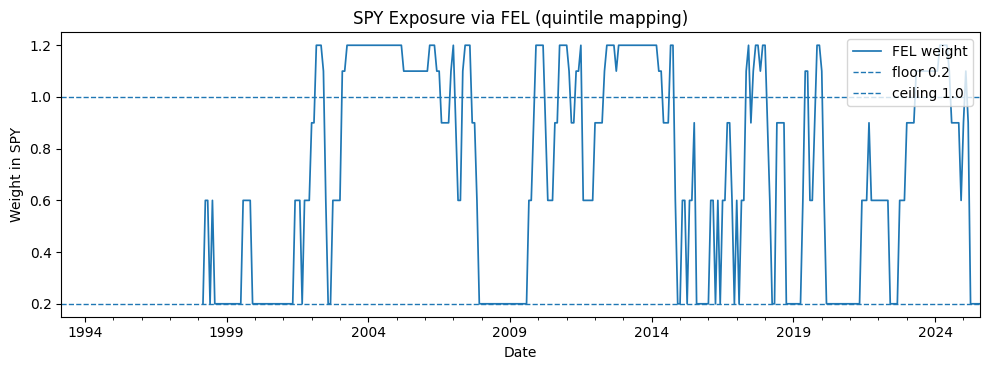

In [22]:

plt.figure(figsize=(10,3.8))
w_phti_fel.plot(label="FEL weight", linewidth=1.25)
plt.axhline(0.2, linestyle="--", linewidth=1, label="floor 0.2")
plt.axhline(1.0, linestyle="--", linewidth=1, label="ceiling 1.0")
plt.title("SPY Exposure via FEL (quintile mapping)")
plt.xlabel("Date"); plt.ylabel("Weight in SPY")
plt.legend(loc="upper right"); plt.tight_layout()
plt.show()


In [23]:
# Map each month into a quintile using trailing 60 months, then compute next-month SPY average return
sig = PHTI_m.dropna()
quints = []
for i in range(60, len(sig)):
    ref = sig.iloc[i-60:i]                   # trailing window
    x   = sig.iloc[i]
    edges = ref.quantile([0.2,0.4,0.6,0.8]).values
    q = 1 + (x > edges).sum()                # 1..5
    quints.append((sig.index[i], q))
qser = pd.Series({d:q for d,q in quints})
qser.name = "Q"

# next-month returns
nx = spy_ret_m.shift(-1)                     # return of month t+1
dfq = pd.concat([qser, nx], axis=1).dropna()
grp = dfq.groupby("Q")[nx.name].mean()       # conditional mean next-month return


In [24]:
# mappings (weights are fractions of SPY; remainder goes to T-bill)
WCP = {1:1.00, 2:1.00, 3:1.00, 4:1.00, 5:0.00}   # Worst-Case Protection
FE  = {1:1.00, 2:0.80, 3:0.60, 4:0.40, 5:0.20}   # Fixed Exposure
FEL = {1:1.20, 2:1.10, 3:0.90, 4:0.60, 5:0.20}   # Fixed Exposure, Levered

# compute October's quintile with trailing 60 months (no look-ahead)
sig = PHTI_m.dropna()
if len(sig) < 61:
    raise ValueError("Not enough monthly PHTI history (need at least 61 months).")

last_m = sig.index.max()                      # e.g., 2025-10-31 (October month-end)
ref_end = last_m - pd.offsets.MonthEnd(1)     # end of September
ref_win = sig.loc[:ref_end].iloc[-60:]        # trailing 60 months up to Sep
edges = ref_win.quantile([0.2,0.4,0.6,0.8]).values

x_oct = sig.loc[last_m]
q_oct = int(1 + (x_oct > edges).sum())        # 1..5

# --- map to November weights ---
w_wcp = WCP[q_oct]
w_fe  = FE[q_oct]
w_fel = FEL[q_oct]

nov_m = last_m + pd.offsets.MonthEnd(1)       # November month-end label

print(f"October PHTI value: {float(x_oct):.6f}")
print(f"October quintile: Q{q_oct}")
print(f"For {nov_m.date()} (November) weights:")
print(f"  WCP: {w_wcp*100:.0f}% SPY, {100 - w_wcp*100:.0f}% T-bill")
print(f"   FE: {w_fe*100:.0f}% SPY, {100 - w_fe*100:.0f}% T-bill")
print(f"  FEL: {w_fel*100:.0f}% SPY, {100 - w_fel*100:.0f}% T-bill")


October PHTI value: 0.025018
October quintile: Q5
For 2025-09-30 (November) weights:
  WCP: 0% SPY, 100% T-bill
   FE: 20% SPY, 80% T-bill
  FEL: 20% SPY, 80% T-bill



=== Single-Strategy Summary (monthly OOS) ===
          ann_ret  ann_vol  sharpe   maxDD
T-Bill     0.0176   0.0052  3.3928  0.0000
PHTI-FEL   0.0791   0.1021  0.7751 -0.2698
OTI-FEL    0.0832   0.1274  0.6528 -0.4340
SPY        0.0963   0.1554  0.6197 -0.5078


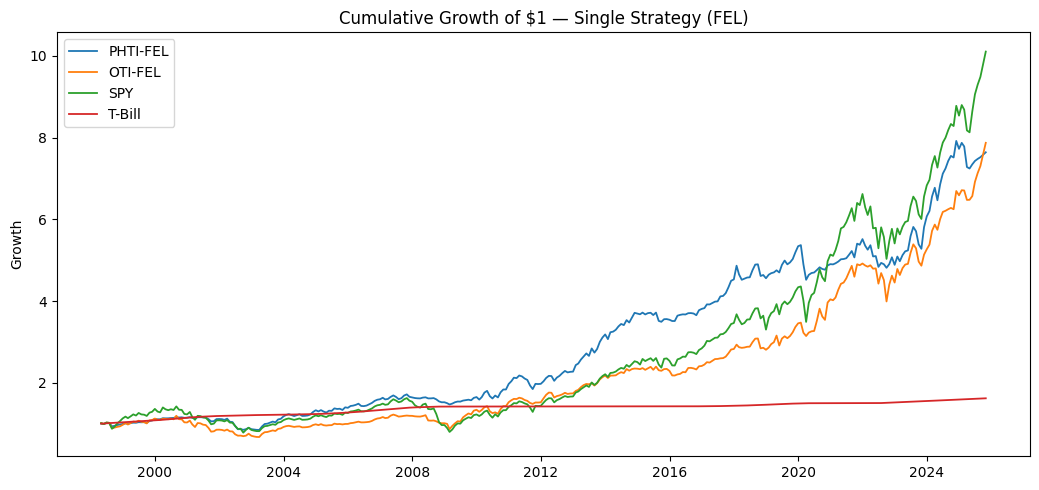

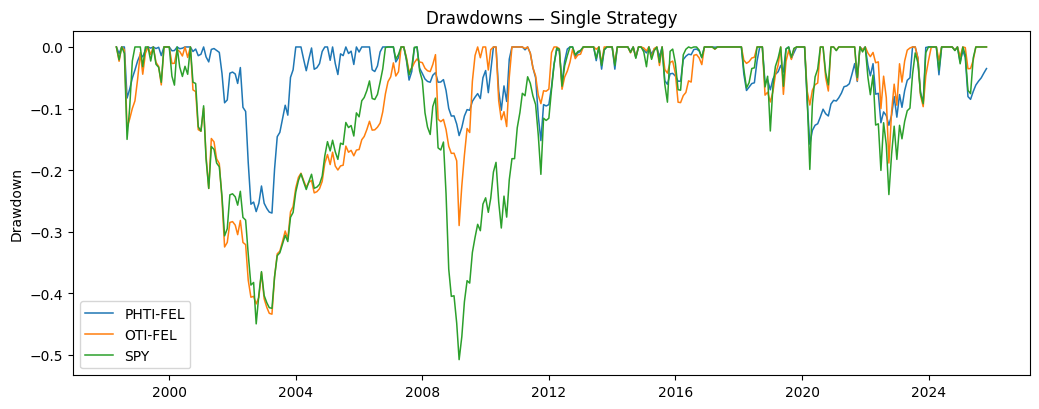

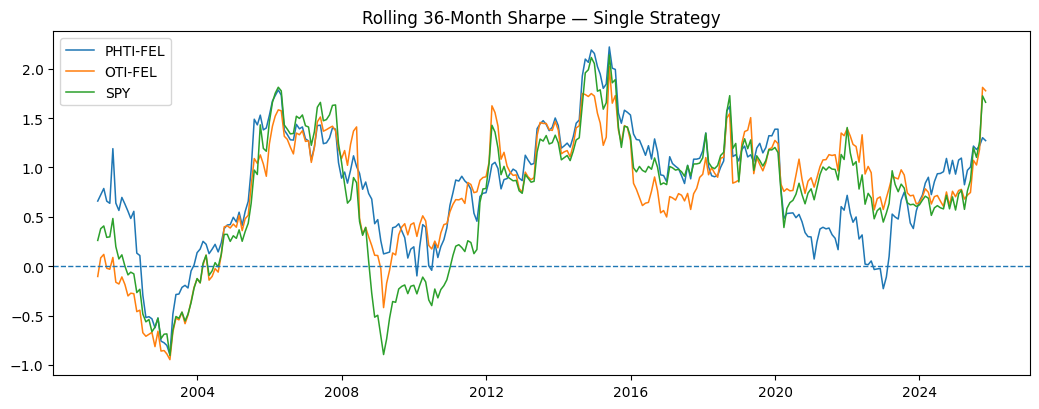

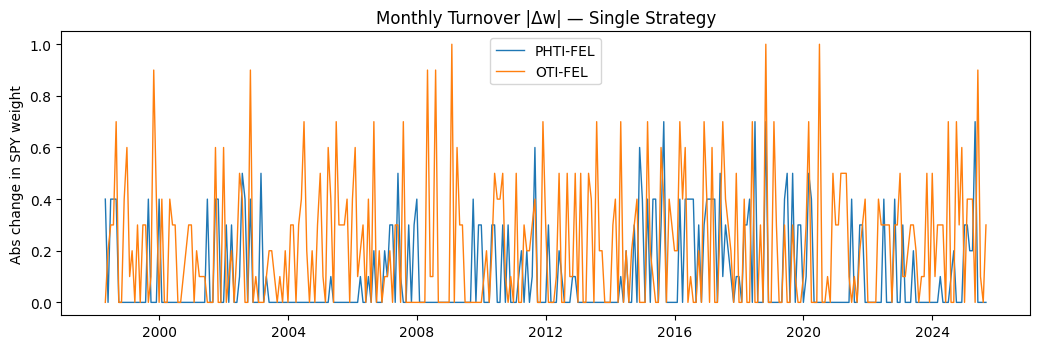

In [25]:
# SINGLE-STRATEGY COMPARISON (FEL)

SCHEME = "FEL"  # change to "WCP" or "FEL" if you want

# 1) Build one set of weights
w_phti = monthend_quintile_weights(PHTI_m, memory_months=phti_cfg.memory_months, scheme=SCHEME)
w_oti  = monthend_quintile_weights(OTI_m,  memory_months=60, scheme=SCHEME)

# 2) Backtests (OOS, apply month t weight to month t+1)
bt_phti = backtest_spy_tbill(w_phti, spy_ret_m, tbill_m).rename(f"PHTI-{SCHEME}")
bt_oti  = backtest_spy_tbill(w_oti,  spy_ret_m, tbill_m).rename(f"OTI-{SCHEME}")

# 3) Align with SPY and T-Bill
cmp_df = pd.concat([bt_phti, bt_oti, spy_ret_m.rename("SPY"), tbill_m.rename("T-Bill")], axis=1).dropna()

# 4) Quick summary
def _mdd(r):
    curve = (1 + r.dropna()).cumprod()
    return float((curve/curve.cummax() - 1.0).min())

summary = []
for col in cmp_df.columns:
    r = cmp_df[col].dropna()
    ann_ret = 12*r.mean()
    ann_vol = np.sqrt(12)*r.std(ddof=1)
    sharpe  = ann_ret/ann_vol if ann_vol>0 else np.nan
    summary.append(pd.Series({
        "ann_ret": ann_ret,
        "ann_vol": ann_vol,
        "sharpe": sharpe,
        "maxDD": _mdd(r)
    }, name=col))
summary = pd.DataFrame(summary).round(4)
print("\n=== Single-Strategy Summary (monthly OOS) ===")
print(summary.sort_values("sharpe", ascending=False))


# 5) Equity curves
eq = (1 + cmp_df).cumprod()
plt.figure(figsize=(10.5,5.0))
for col in [f"PHTI-{SCHEME}", f"OTI-{SCHEME}", "SPY", "T-Bill"]:
    plt.plot(eq.index, eq[col], label=col, linewidth=1.3)
plt.title(f"Cumulative Growth of $1 — Single Strategy ({SCHEME})")
plt.ylabel("Growth"); plt.legend(); plt.tight_layout(); plt.show()

# 6) Drawdowns (PHTI, OTI, SPY)
def _dd_series(r):
    c = (1 + r.dropna()).cumprod(); p = c.cummax()
    return (c/p - 1.0)

plt.figure(figsize=(10.5,4.2))
for col in [f"PHTI-{SCHEME}", f"OTI-{SCHEME}", "SPY"]:
    plt.plot(_dd_series(cmp_df[col]), label=col, linewidth=1.1)
plt.title("Drawdowns — Single Strategy"); plt.ylabel("Drawdown")
plt.legend(); plt.tight_layout(); plt.show()

# 7) Rolling 36M Sharpe
win = 36
roll = {}
for col in [f"PHTI-{SCHEME}", f"OTI-{SCHEME}", "SPY"]:
    r = cmp_df[col]
    mu = r.rolling(win).mean()*12
    sd = r.rolling(win).std(ddof=1)*np.sqrt(12)
    roll[col] = (mu/sd)
roll_df = pd.concat(roll, axis=1).dropna()

plt.figure(figsize=(10.5,4.2))
for col in roll_df.columns:
    plt.plot(roll_df.index, roll_df[col], label=col, linewidth=1.1)
plt.axhline(0.0, linestyle="--", linewidth=1)
plt.title("Rolling 36-Month Sharpe — Single Strategy")
plt.legend(); plt.tight_layout(); plt.show()

# 8) Turnover time-series (monthly)
def _turnover_ts(w):
    return w.dropna().diff().abs().rename("turnover")

turno = pd.concat({
    f"PHTI-{SCHEME}": _turnover_ts(w_phti),
    f"OTI-{SCHEME}":  _turnover_ts(w_oti),
}, axis=1).dropna()

plt.figure(figsize=(10.5,3.6))
for col in turno.columns:
    plt.plot(turno.index, turno[col], label=col, linewidth=1.0)
plt.title("Monthly Turnover |Δw| — Single Strategy")
plt.ylabel("Abs change in SPY weight")
plt.legend(); plt.tight_layout(); plt.show()



=== Single-Strategy Summary (monthly OOS, up to 2020-12-31) ===
         ann_ret  ann_vol  sharpe   maxDD
T-Bill    0.0180   0.0055  3.2452  0.0000
PHTI-FE   0.0642   0.0768  0.8360 -0.2127
OTI-FE    0.0562   0.0962  0.5839 -0.3340
SPY       0.0843   0.1554  0.5427 -0.5078


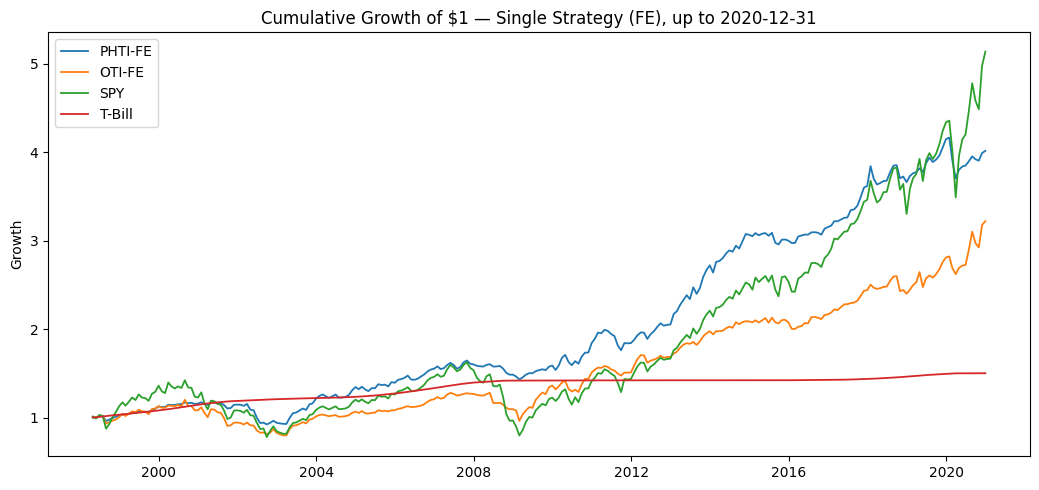

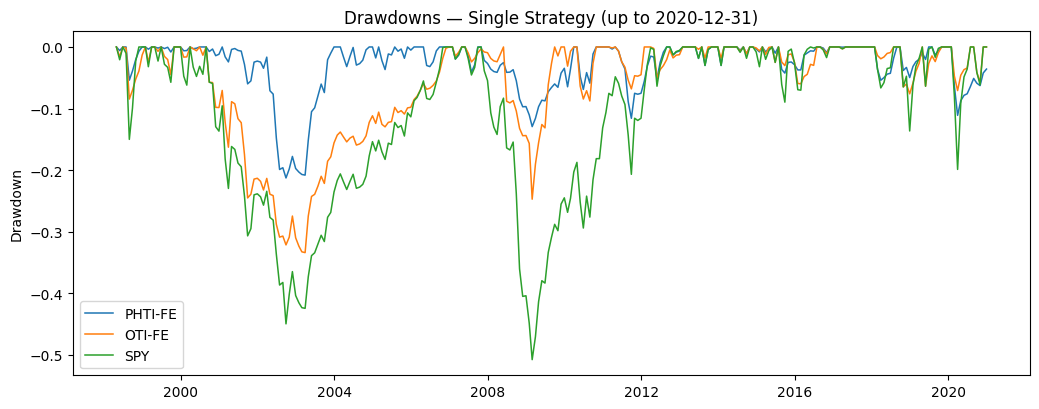

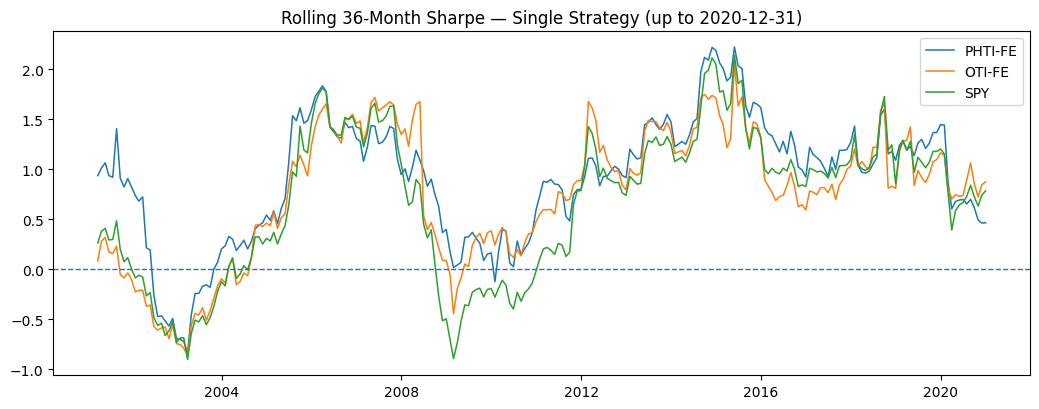

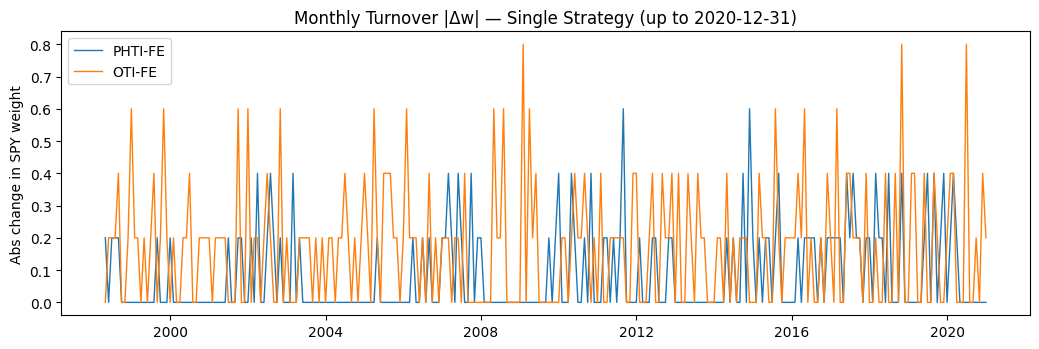

In [26]:
# SINGLE-STRATEGY COMPARISON (FE)

SCHEME   = "FE"           # change to "WCP" or "FEL" if you want
END_DATE = "2020-12-31"    # limit all charts/data here

# 1) Build one set of weights
w_phti = monthend_quintile_weights(PHTI_m, memory_months=phti_cfg.memory_months, scheme=SCHEME)
w_oti  = monthend_quintile_weights(OTI_m,  memory_months=60,                  scheme=SCHEME)

# 2) Backtests (OOS, apply month t weight to month t+1)
bt_phti = backtest_spy_tbill(w_phti, spy_ret_m, tbill_m).rename(f"PHTI-{SCHEME}")
bt_oti  = backtest_spy_tbill(w_oti,  spy_ret_m, tbill_m).rename(f"OTI-{SCHEME}")

w_vix  = monthend_quintile_weights(VIX_m,  memory_months=60, scheme=SCHEME)
bt_vix = backtest_spy_tbill(w_vix,  spy_ret_m, tbill_m).rename(f"VIX-{SCHEME}")


# 3) Align with SPY and T-Bill, then truncate to END_DATE
cmp_df = pd.concat(
    [bt_phti, bt_oti, spy_ret_m.rename("SPY"), tbill_m.rename("T-Bill")],
    axis=1
).dropna()

cmp_df = cmp_df.loc[:END_DATE]   # << all subsequent stats/plots only up to 2020-12-31

# 4) summary on truncated sample
def _mdd(r):
    curve = (1 + r.dropna()).cumprod()
    return float((curve/curve.cummax() - 1.0).min())

summary = []
for col in cmp_df.columns:
    r = cmp_df[col].dropna()
    ann_ret = 12 * r.mean()
    ann_vol = np.sqrt(12) * r.std(ddof=1)
    sharpe  = ann_ret / ann_vol if ann_vol > 0 else np.nan
    summary.append(pd.Series({
        "ann_ret": ann_ret,
        "ann_vol": ann_vol,
        "sharpe": sharpe,
        "maxDD": _mdd(r)
    }, name=col))

summary = pd.DataFrame(summary).round(4)
print("\n=== Single-Strategy Summary (monthly OOS, up to 2020-12-31) ===")
print(summary.sort_values("sharpe", ascending=False))

# 5) Equity curves (truncated via cmp_df already)
eq = (1 + cmp_df).cumprod()

plt.figure(figsize=(10.5, 5.0))
for col in [f"PHTI-{SCHEME}", f"OTI-{SCHEME}", "SPY", "T-Bill"]:
    plt.plot(eq.index, eq[col], label=col, linewidth=1.3)
plt.title(f"Cumulative Growth of $1 — Single Strategy ({SCHEME}), up to {END_DATE}")
plt.ylabel("Growth")
plt.legend()
plt.tight_layout()
plt.show()

# 6) Drawdowns (PHTI, OTI, SPY) on truncated sample
def _dd_series(r):
    c = (1 + r.dropna()).cumprod()
    p = c.cummax()
    return (c / p - 1.0)

plt.figure(figsize=(10.5, 4.2))
for col in [f"PHTI-{SCHEME}", f"OTI-{SCHEME}", "SPY"]:
    dd = _dd_series(cmp_df[col])
    plt.plot(dd.index, dd, label=col, linewidth=1.1)
plt.title(f"Drawdowns — Single Strategy (up to {END_DATE})")
plt.ylabel("Drawdown")
plt.legend()
plt.tight_layout()
plt.show()

# 7) Rolling 36M Sharpe (computed and plotted only up to END_DATE)
win = 36
roll = {}
for col in [f"PHTI-{SCHEME}", f"OTI-{SCHEME}", "SPY"]:
    r  = cmp_df[col]
    mu = r.rolling(win).mean() * 12
    sd = r.rolling(win).std(ddof=1) * np.sqrt(12)
    roll[col] = (mu / sd)

roll_df = pd.concat(roll, axis=1).dropna()

plt.figure(figsize=(10.5, 4.2))
for col in roll_df.columns:
    plt.plot(roll_df.index, roll_df[col], label=col, linewidth=1.1)
plt.axhline(0.0, linestyle="--", linewidth=1)
plt.title(f"Rolling 36-Month Sharpe — Single Strategy (up to {END_DATE})")
plt.legend()
plt.tight_layout()
plt.show()

# 8) Turnover time-series (monthly) truncated to END_DATE
def _turnover_ts(w):
    return w.dropna().diff().abs().rename("turnover")

turno = pd.concat({
    f"PHTI-{SCHEME}": _turnover_ts(w_phti.loc[:END_DATE]),
    f"OTI-{SCHEME}":  _turnover_ts(w_oti.loc[:END_DATE]),
}, axis=1).dropna()

plt.figure(figsize=(10.5, 3.6))
for col in turno.columns:
    plt.plot(turno.index, turno[col], label=col, linewidth=1.0)
plt.title(f"Monthly Turnover |Δw| — Single Strategy (up to {END_DATE})")
plt.ylabel("Abs change in SPY weight")
plt.legend()
plt.tight_layout()
plt.show()


In [30]:
# ===================================
# Export data to use in the dashboard
# ===================================

# Ignore this part
# 1. Create the dashboard folder
# os.makedirs("dashboard", exist_ok=True)

# 2. Compile all relevant data into one DataFrame
# Merge on Date index
export_df = pd.DataFrame(index=spy_ret_m.index)

# Assets
export_df["SPY"] = spy_ret_m
export_df["TBill"] = tbill_m

# Signals (Regime Indicators)
export_df["Signal_PHTI"] = PHTI_m
export_df["Signal_OTI"] = OTI_m
export_df["Signal_VIX"] = VIX_m

# Weights (Equity Exposure)
# We save PHTI weights for all schemes. 
export_df["Wgt_PHTI_WCP"] = w_phti_wcp
export_df["Wgt_PHTI_FE"]  = w_phti_fe
export_df["Wgt_PHTI_FEL"] = w_phti_fel

# Strategy Returns
export_df["Ret_PHTI_WCP"] = bt_phti_wcp
export_df["Ret_PHTI_FE"]  = bt_phti_fe
export_df["Ret_PHTI_FEL"] = bt_phti_fel

export_df["Ret_OTI_WCP"] = bt_oti_wcp
export_df["Ret_VIX_WCP"] = bt_vix_wcp

# 3. Clean up and Save
export_df = export_df.dropna(how='all').sort_index()
export_df.index.name = "Date"
export_df.reset_index(inplace=True)

export_df["Date"] = pd.to_datetime(export_df["Date"], errors="coerce")

# Coerce Date if formatted as epoch ints
if export_df["Date"].isna().any():
    raw = pd.to_numeric(export_df["Date"], errors="coerce")
    if raw.notna().any():
        med = raw.dropna().median()
        unit = "ns" if med > 1e14 else ("ms" if med > 1e11 else "s")
        export_df["Date"] = pd.to_datetime(raw.astype("int64"), unit=unit, origin="unix", errors="coerce")

export_df = export_df.dropna(subset=["Date"]).sort_values("Date")

export_df.to_csv("phti_data.csv", index=False, date_format="%Y-%m-%d")


# Save to the dashboard folder
export_df.to_csv("phti_data.csv", index=False)

print(f"Data exported successfully to: {os.path.abspath('phti_data.csv')}")
# IMPORTANT: Move this output file to 'QWIM-Market-Regimes/src/dashboard' for the data to be parsed by the dashboard.

Data exported successfully to: /Users/vineel/Desktop/College/800/PHTI_implementation/code/phti_data.csv
